# Country-Level Analysis of Temperature and Precipitation Trends

Weather predictions and climate projections are the backbone for developing tailored climate services for communities that urgently need to roll out adaptation plans and undertake risk management ([WMO, 2023](https://wmo.int/resources/wmo-bulletin/wmo-bulletin-vol-72-2-2023/climate-services-based-climate-predictions-and-projections)). This is key in countries highly susceptible to climate change, where ongoing conflicts amplify climate risks and, consequently, their impacts.

This notebook relies on state-of-the-art climate datasets, namely the ERA5 reanalysis and climate model simulations from the [Coordinated Regional Downscaling Experiment (CORDEX) Coordinated Output for Regional Evaluations (CORE) ensemble](https://cordex.org/experiment-guidelines/cordex-cmip5/cordex-core/cordex-core-simulations/). The ensemble comprises two regional climate models (RCMs) driven by three global climate models (GCMs). We analyse temperature- and precipitation-based indicators over the period 1980–2100.

In [1]:
import numpy as np
import pandas as pd
import xarray

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

import cavapy
from cavapy.data import load_era5, load_cordex_core
from cavapy.countries import Country
from cavapy.indices import mean_and_trend

from utils import plot_annual_mean_and_trend, plot_biases
from utils import load_scenarios, plot_scenarios

This notebook can be adapted to any country in the world, as the ERA5 datasets provide global coverage. For the selected country, the appropriate CORDEX-CORE domain must be identified to retrieve the corresponding CORDEX data.

This document presents the results of the notebook run for the following country:

In [2]:
DOMAIN  = "AFR-22" # required for CORDEX-CORE climate model data (AFR-22, CAM-22, NAM-22, SAM-22, EUR-22, WAS-22, EAS-22, CAS-22, SEA-22, AUS-22)
country = Country("Yemen") # if running in Binder, switch to "Togo" for a run with minimal memory constraints
min_lon, min_lat, max_lon, max_lat = country.bbox
min_lon, min_lat, max_lon, max_lat = min_lon - 1, min_lat - 1, max_lon + 1, max_lat + 1

# the period of our analysis
DATE0, DATE1 = "1980-01-01", "2005-12-31"
YEARS        = np.arange(1980, 2006)

# values for vmin and vmax in plots
q0, q1 = .05, .95

print(f"{DOMAIN}, {country}")

AFR-22, Yemen: (42.604873, 12.58595, 53.108573, 19.000003)


## The observational dataset (ERA5)

ERA5 ([Hersbach et al., 2020](https://doi.org/10.1002/qj.3803)) is a global atmospheric reanalysis dataset that provides consistent and spatially continuous climate information, making it a valuable source of meteorological data for climate analysis, particularly in regions where in situ observations are limited.

ERA5 provides hourly data on a global grid at a spatial resolution of 0.25° (approximately 25 km), covering the period from 1940 to the present. It includes a wide range of atmospheric and surface variables, enabling the analysis of historical climate conditions and variability.

In this notebook, ERA5 is used to derive daily minimum and maximum temperatures and daily accumulated precipitation, which serve as the basis for calculating temperature- and precipitation-based climate indicators. The analysis period is determined by the temporal overlap between ERA5 data and the historical regional climate model simulations from the CORDEX-CORE ensemble.


### Loading ERA5 data

ERA5 data for this analysis will be retrieved from the CAVA climate data infrastructure, which provides remote data access over the internet through the OPeNDAP protocol. This service is supported by the THREDDS Data Server (TDS) hosted by the Instituto de Física de Cantabria (IFCA, CSIC-UC, Spain).

Since the data are accessed remotely, loading times will depend on the amount of data requested, the network connection, and the server's response time. Data retrieval for large countries may therefore take longer, as the requested data must be transferred from the remote server to the workstation running the notebook.

In [3]:
%%time

vs = ["tp", "t2mx", "t2mn"]
era5 = load_era5(
    xarray.open_dataset("https://hub.ipcc.ifca.es/thredds/dodsC/fao/observations/ERA5/0.25/ERA5_025.ncml").drop_vars(["number"]),
    vs,
    (DATE0, DATE1),
    (min_lat, max_lat),
    (min_lon, max_lon))

# convert units
era5["tp"] = era5["tp"] * 1000 # from m to mm
era5["tp"].attrs["units"] = "mm"
era5["t2mx"] = era5["t2mx"] - 273.15 # from K to C
era5["t2mx"].attrs["units"] = "C°"
era5["t2mn"] = era5["t2mn"] - 273.15 # from K to C
era5["t2mn"].attrs["units"] = "C°"

print(f"Loaded data: dataset = ERA5, variables = {vs}, time period = ({DATE0}, {DATE1}), country = {country}.\n")

Loaded data: dataset = ERA5, variables = ['tp', 't2mx', 't2mn'], time period = (1980-01-01, 2005-12-31), country = Yemen: (42.604873, 12.58595, 53.108573, 19.000003).

CPU times: user 588 ms, sys: 663 ms, total: 1.25 s
Wall time: 12.3 s


### Compute precipitation indices, annual means and trends

A total of five precipitation-based indicators (PRCPTOT, DD, CDD, CWD, and R20)  are considered in this analysis. Several of these indicators are recommended by the World Climate Research Programme (WCRP) Expert Team on Climate Change Detection and Indices ([ETCCDI](https://etccdi.pacificclimate.org/)).

In [4]:
prcptot = cavapy.indices.prcptot(era5["tp"])
dd = cavapy.indices.dd(era5["tp"])
cdd = cavapy.indices.cdd(era5["tp"])
cwd = cavapy.indices.cwd(era5["tp"])
r20 = cavapy.indices.r20(era5["tp"])

prcptot_annual_mean, prcptot_trend, prcptot_pvalue = mean_and_trend(prcptot, YEARS)
dd_annual_mean, dd_trend, dd_pvalue = mean_and_trend(dd, YEARS)
cdd_annual_mean, cdd_trend, cdd_pvalue = mean_and_trend(cdd, YEARS)
cwd_annual_mean, cwd_trend, cwd_pvalue = mean_and_trend(cwd, YEARS)
r20_annual_mean, r20_trend, r20_pvalue = mean_and_trend(r20, YEARS)

results = xarray.Dataset({
    "prcptot_mean": prcptot_annual_mean,
    "prcptot_trend": prcptot_trend,
    "prcptot_pvalue": prcptot_pvalue,

    "dd_mean": dd_annual_mean,
    "dd_trend": dd_trend,
    "dd_pvalue": dd_pvalue,

    "r20_mean": r20_annual_mean,
    "r20_trend": r20_trend,
    "r20_pvalue": r20_pvalue,

    "cdd_mean": cdd_annual_mean,
    "cdd_trend": cdd_trend,
    "cdd_pvalue": cdd_pvalue,

    "cwd_mean": cwd_annual_mean,
    "cwd_trend": cwd_trend,
    "cwd_pvalue": cwd_pvalue,
})

We now show the annual mean climatology (left column) and yearly trends (right column) derived from ERA5 for the different precipitation-based indicators considered (in rows) along the period 1980-2005.

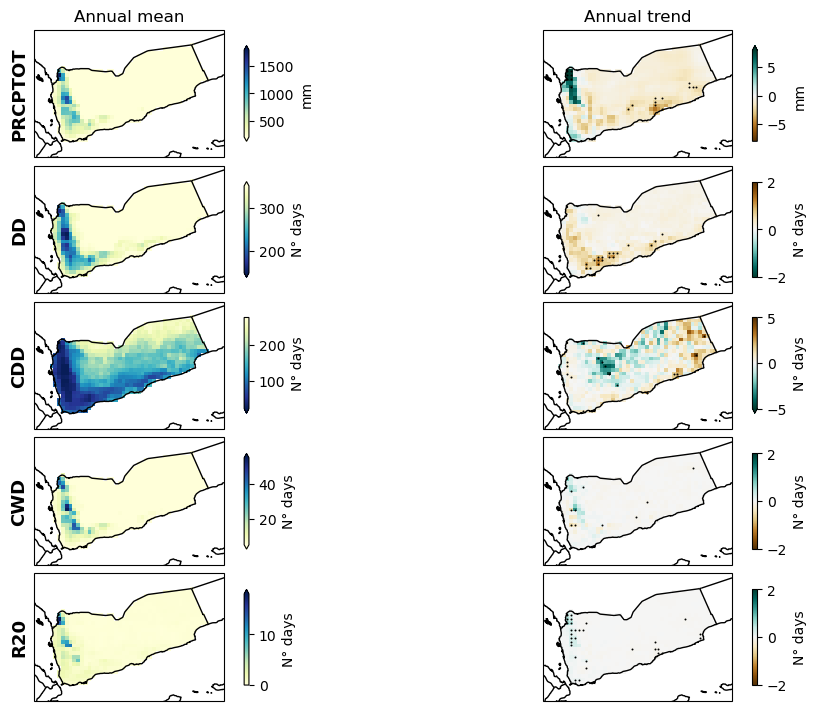

In [5]:
settings = {
    "prcptot": { "mean": {"cmap": "YlGnBu", "vmin": 200, "vmax": 1800}, "trend": {"cmap": "BrBG", "vmin": -8, "vmax": 8} },
    "dd": { "mean": {"cmap": "YlGnBu_r", "vmin": 150, "vmax": 350}, "trend": {"cmap": "BrBG_r", "vmin": -2, "vmax": 2} },
    "cdd": { "mean": {"cmap": "YlGnBu_r", "vmin": 25, "vmax": 275}, "trend": {"cmap": "BrBG_r", "vmin": -5, "vmax": 5} },
    "cwd": { "mean": {"cmap": "YlGnBu", "vmin": 5, "vmax": 55}, "trend": {"cmap": "BrBG", "vmin": -2, "vmax": 2} },
    "r20": { "mean": {"cmap": "YlGnBu", "vmin": 0, "vmax": 18}, "trend": {"cmap": "BrBG", "vmin": -2, "vmax": 2} },
}

indices = list(settings.keys())
columns = ["mean", "trend"]
titles = ["Annual mean", "Annual trend"]
mask = country.mask(era5["latitude"].values, era5["longitude"].values)

fig, axes = plot_annual_mean_and_trend(results, mask, settings, indices, columns, titles, (min_lon, max_lon, min_lat, max_lat))
plt.show()

### Compute temperature indices, annual means and trends

A total of three temperature-based indicators (SU, TR and HWVS)  are considered in this analysis. Several of these indicators are recommended by the World Climate Research Programme (WCRP) Expert Team on Climate Change Detection and Indices ([ETCCDI](https://etccdi.pacificclimate.org/)).

In [6]:
su = cavapy.indices.su(era5["t2mx"])
tr = cavapy.indices.tr(era5["t2mn"])
hwvs = cavapy.indices.hwvs(era5["t2mx"])

su_annual_mean, su_trend, su_pvalue = mean_and_trend(su, YEARS)
tr_annual_mean, tr_trend, tr_pvalue = mean_and_trend(tr, YEARS)
hwvs_annual_mean, hwvs_trend, hwvs_pvalue = mean_and_trend(hwvs, YEARS)

results = xarray.Dataset({
    "su_mean": su_annual_mean,
    "su_trend": su_trend,
    "su_pvalue": su_pvalue,

    "tr_mean": tr_annual_mean,
    "tr_trend": tr_trend,
    "tr_pvalue": tr_pvalue,

    "hwvs_mean": hwvs_annual_mean,
    "hwvs_trend": hwvs_trend,
    "hwvs_pvalue": hwvs_pvalue,
})

We now show the annual mean climatology (left column) and yearly trends (right column) derived from ERA5 for the different temperature-based indicators considered (in rows) along the period 1980-2005.

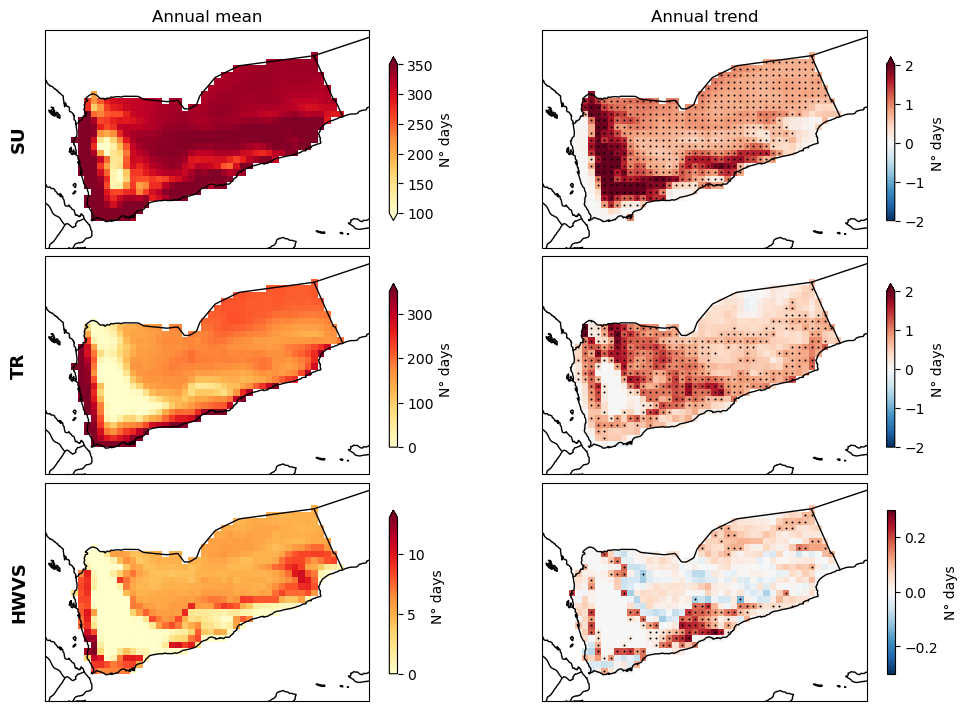

In [7]:
settings = {
    "su": { "mean": {"cmap": "YlOrRd", "vmin": 100, "vmax": 350}, "trend": {"cmap": "RdBu_r", "vmin": -2, "vmax": 2} },
    "tr": { "mean": {"cmap": "YlOrRd", "vmin": 0, "vmax": 350}, "trend": {"cmap": "RdBu_r", "vmin": -2, "vmax": 2} },
    "hwvs": { "mean": {"cmap": "YlOrRd", "vmin": 0, "vmax": 13}, "trend": {"cmap": "RdBu_r", "vmin": -0.3, "vmax": 0.3} },
}

indices = list(settings.keys())
columns = ["mean", "trend"]
titles = ["Annual mean", "Annual trend"]
mask = country.mask(era5["latitude"].values, era5["longitude"].values)

fig, axes = plot_annual_mean_and_trend(results, mask, settings, indices, columns, titles, (min_lon, max_lon, min_lat, max_lat))
plt.show()

## The CORDEX-CORE Climate Model Simulation Ensemble

Daily minimum and maximum temperatures, together with daily accumulated precipitation, are obtained from the CORDEX-CORE ensemble. The CORDEX-CORE initiative aims to establish a consistent global framework for regional climate modelling, providing high-resolution regional climate projections for most inhabited land regions through nine CORDEX domains at a spatial resolution of approximately 0.22°.

The ensemble comprises simulations from three Global Climate Models (GCMs)-HadGEM2-ES, MPI-ESM, and NorESM-representing high, medium, and low equilibrium climate sensitivities, respectively. These GCMs were dynamically downscaled using two Regional Climate Models (RCMs), REMO and RegCM4, under two Representative Concentration Pathways (RCPs): RCP2.6, representing a low-emissions scenario, and RCP8.5, representing a high-emissions scenario ([Coppola et al., 2021](https://doi.org/10.1007/s00382-021-05640-z); [Teichmann et al., 2021](https://doi.org/10.1007/s00382-020-05494-x)).

CORDEX-CORE provides historical simulations covering 1970-2005, as well as future projections extending to 2100. Historical simulations can be used to evaluate model performance against reference datasets, while future projections enable the assessment of potential climate trends under different emissions scenarios.

For consistency with the ERA5 reference dataset, the regional climate model data are interpolated onto the ERA5 grid using first-order conservative remapping. The appropriate CORDEX-CORE domain is selected according to the geographical location of the country under analysis. Where a country falls within multiple CORDEX domains, the domain selection should be specified explicitly.

In [8]:
df = pd.read_csv("https://hub.ipcc.ifca.es/thredds/fileServer/inventories/cava.csv")

subset_raw = df[(df["location"].str.contains(DOMAIN)) & (df["location"].str.contains('/historical/')) & (df["location"].str.contains('/interp025/'))]
subset_bc  = df[(df["location"].str.contains(DOMAIN)) & (df["location"].str.contains('/historical/')) & (df["location"].str.contains('/interp025bc/'))]

max_lat, min_lat, min_lon, max_lon = (
    era5["latitude"].max().item(),
    era5["latitude"].min().item(),
    era5["longitude"].min().item(),
    era5["longitude"].max().item())

As with ERA5, CORDEX-CORE data for this analysis will be retrieved from the CAVA climate data infrastructure, which provides remote data access over the internet through the OPeNDAP protocol. This service is supported by the THREDDS Data Server (TDS) hosted by the Instituto de Física de Cantabria (IFCA, CSIC-UC, Spain).

Since the data are accessed remotely, loading times will depend on the amount of data requested, the network connection, and the server's response time. Data retrieval for large countries may therefore take longer, as the requested data must be transferred from the remote server to the workstation running the notebook.

In [9]:
%%time

vs = ["pr", "tasmin", "tasmax"]
ds_raw = load_cordex_core(subset_raw, vs, (DATE0, "2006-01-01"), (max_lat, min_lat), (min_lon, max_lon))
ds_bc  = load_cordex_core(subset_bc , vs, (DATE0, "2006-01-01"), (max_lat, min_lat), (min_lon, max_lon))

print(f"Loaded data: dataset = CORDEX-CORE, variables = {vs}, time period = ({DATE0}, \"2006-01-01\").")
print(f"Loaded data: dataset = CORDEX-CORE (bias corrected), variables = {vs}, time period = ({DATE0}, \"2006-01-01\").\n")

Loaded data: dataset = CORDEX-CORE, variables = ['pr', 'tasmin', 'tasmax'], time period = (1980-01-01, "2006-01-01").
Loaded data: dataset = CORDEX-CORE (bias corrected), variables = ['pr', 'tasmin', 'tasmax'], time period = (1980-01-01, "2006-01-01").

CPU times: user 6.3 s, sys: 8.3 s, total: 14.6 s
Wall time: 16min 34s


## Compute historical climate index biases

Although regional climate models (RCMs) can represent regional climate patterns in detail, their simulations may exhibit systematic biases that limit their direct use in climate impact assessments. Statistical bias-correction methods are therefore commonly applied to improve the agreement between model simulations and reference datasets, particularly when calculating climate indicators based on specific thresholds ([Casanueva et al., 2020](https://doi.org/10.1002/asl.978)).

In this notebook, the bias-corrected CORDEX-CORE simulations are compared with raw CORDEX-CORE simulations using the ERA5 reanalysis as the reference dataset over the 1980-2005 period. This period is used to establish the reference for bias correction, subject to the temporal overlap and availability of the relevant datasets.

In [10]:
def compute_bias(raw, bc, era5, units, long_name):
    raw = raw.mean("time") - era5.mean("time")
    bc  = bc.mean("time")  - era5.mean("time")
    
    bias = xarray.concat([raw, bc], dim=xarray.IndexVariable("source", ["raw", "bc"]))
    bias.attrs["long_name"] = long_name
    bias.attrs["units"]     = units

    return bias

We now compute and display the biases for the precipitation-related indices.

In [11]:
PRCPTOT = compute_bias(
    cavapy.indices.prcptot(ds_raw["pr"] * 86400),
    cavapy.indices.prcptot(ds_bc["pr"]  * 86400),
    prcptot, "mm", "PRCPTOT")
DD = compute_bias(
    cavapy.indices.dd(ds_raw["pr"] * 86400),
    cavapy.indices.dd(ds_bc["pr"]  * 86400),
    dd, "N° days", "DD")
CDD = compute_bias(
    cavapy.indices.cdd(ds_raw["pr"] * 86400),
    cavapy.indices.cdd(ds_bc["pr"]  * 86400),
    cdd, "N° days", "CDD")
CWD = compute_bias(
    cavapy.indices.cwd(ds_raw["pr"] * 86400),
    cavapy.indices.cwd(ds_bc["pr"]  * 86400),
    cwd, "N° days", "CWD")
R20 = compute_bias(
    cavapy.indices.r20(ds_raw["pr"] * 86400),
    cavapy.indices.r20(ds_bc["pr"]  * 86400),
    r20, "N° days", "R20")

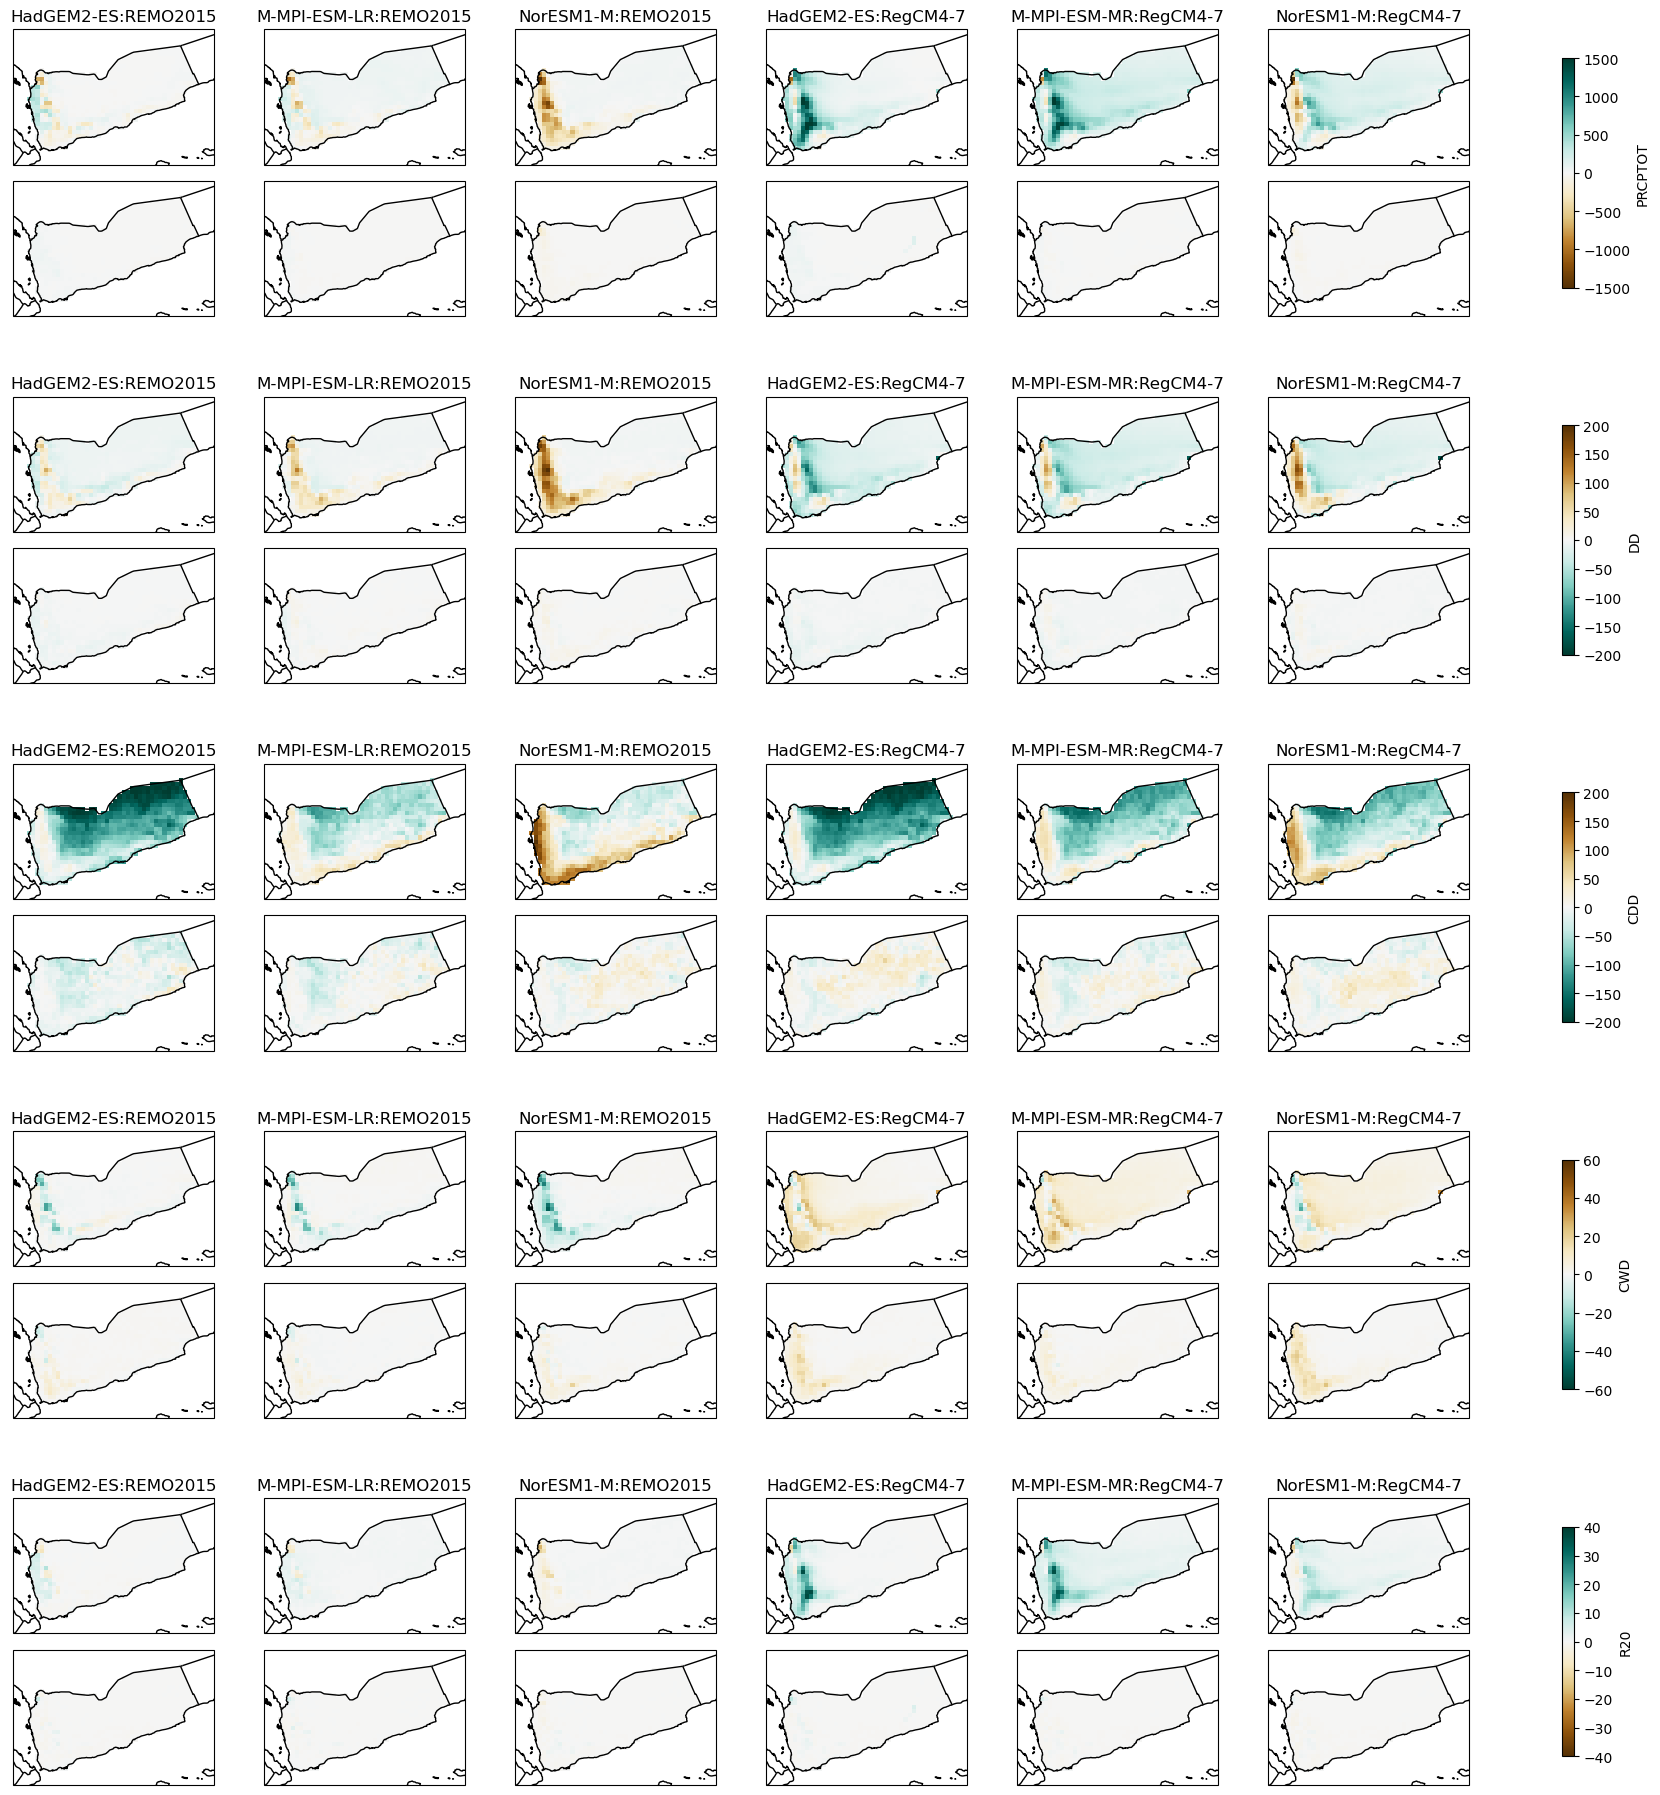

In [12]:
indices = [
    (PRCPTOT.drop_vars(["height"]), "PRCPTOT", -1500, 1500, "BrBG"),
    (DD.drop_vars(["height"]),      "DD",      -200,  200,  "BrBG_r"),
    (CDD.drop_vars(["height"]),     "CDD",     -200,  200,  "BrBG_r"),
    (CWD.drop_vars(["height"]),     "CWD",     -60,   60,   "BrBG_r"),
    (R20.drop_vars(["height"]),     "R20",     -40,   40,   "BrBG"),
]

fig, axs = plot_biases(
    indices=indices,
    mask=mask,
    min_lon=min_lon,
    max_lon=max_lon,
    min_lat=min_lat,
    max_lat=max_lat)

We now compute and display the biases for the temperature-related indices.

In [13]:
SU = compute_bias(
    cavapy.indices.su(ds_raw["tasmax"] - 273.15),
    cavapy.indices.su(ds_bc["tasmax"]  - 273.15),
    su, "N° days", "SU")
TR = compute_bias(
    cavapy.indices.tr(ds_raw["tasmin"] - 273.15),
    cavapy.indices.tr(ds_bc["tasmin"]   - 273.15),
    tr, "N° days", "TR")
HWVS = compute_bias(
    cavapy.indices.hwvs(ds_raw["tasmax"] - 273.15),
    cavapy.indices.hwvs(ds_bc["tasmax"]  - 273.15),
    hwvs, "N° days", "HWVS")

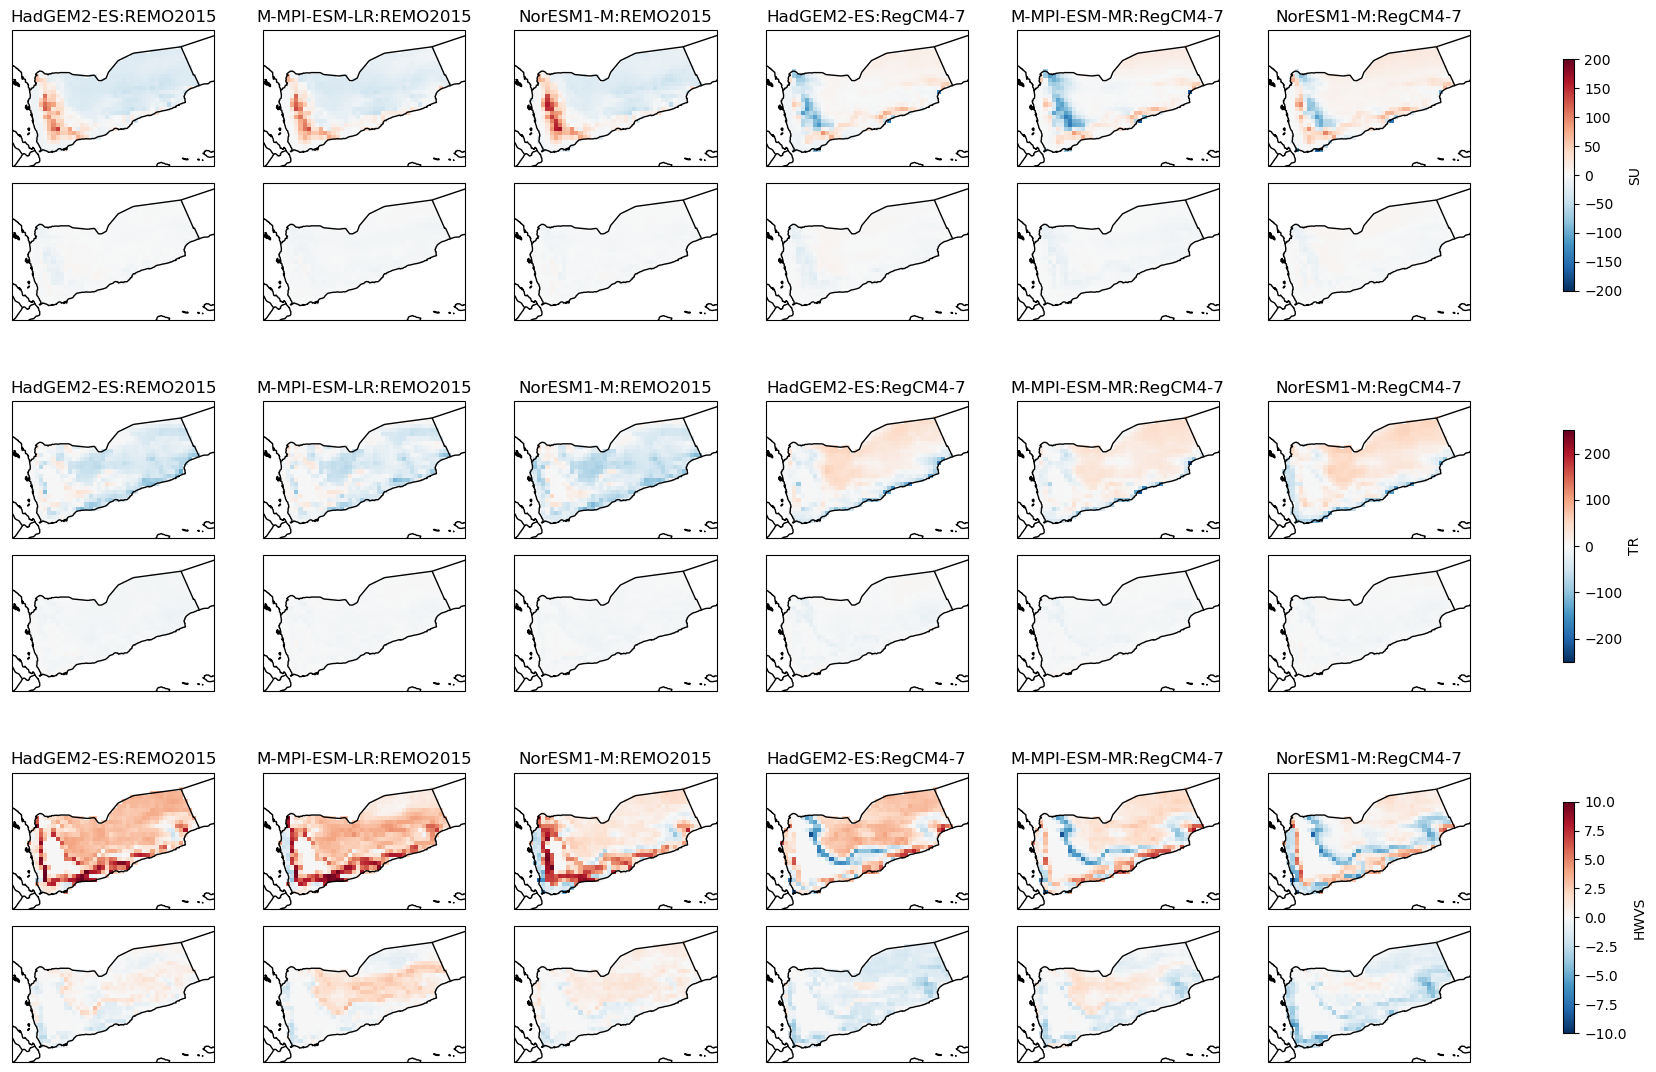

In [14]:
indices = [
    (SU.drop_vars(["height"]),  "SU",   -200,  200, "RdBu_r"),
    (TR.drop_vars(["height"]),  "TR",   -250,  250,  "RdBu_r"),
    (HWVS.drop_vars(["height"]),"HWVS", -10 ,  10 ,  "RdBu_r"),
]

fig, axs = plot_biases(
    indices=indices,
    mask=mask,
    min_lon=min_lon,
    max_lon=max_lon,
    min_lat=min_lat,
    max_lat=max_lat)

## Compute future climate index biases

Bias correction is an important step in climate impact assessments, as systematic biases in regional climate model (RCM) simulations can affect the reliability of climate indicators and their interpretation under future climate conditions. Applying bias-correction methods to future projections helps ensure consistency with the reference dataset while enabling the assessment of projected changes in climate indices.

Now, the bias-corrected CORDEX-CORE simulations are compared with raw CORDEX-CORE simulations for the future climate scenarios RCP2.6 and RCP8.5. The analysis focuses on climate indices derived from the simulations, allowing the differences between corrected and uncorrected projections to be evaluated under contrasting greenhouse gas concentration pathways. The historical period (1980–2005), for which CORDEX-CORE is used as the reference dataset, provides the basis for the bias-correction procedure.

In [15]:
hist = xarray.merge([
            cavapy.indices.prcptot(ds_bc["pr"] * 86400).rename("prcptot"),
            cavapy.indices.dd(ds_bc["pr"] * 86400).rename("dd"),
            cavapy.indices.cdd(ds_bc["pr"] * 86400).rename("cdd"),
            cavapy.indices.cwd(ds_bc["pr"] * 86400).rename("cwd"),
            cavapy.indices.r20(ds_bc["pr"] * 86400).rename("r20"),
            cavapy.indices.su(ds_bc["tasmax"] - 273.15).rename("su"),
            cavapy.indices.tr(ds_bc["tasmin"] - 273.15).rename("tr"),
            cavapy.indices.hwvs(ds_bc["tasmax"] - 273.15).rename("hwvs"),
])

CPU times: user 1min 54s, sys: 19.3 s, total: 2min 13s
Wall time: 26min 30s


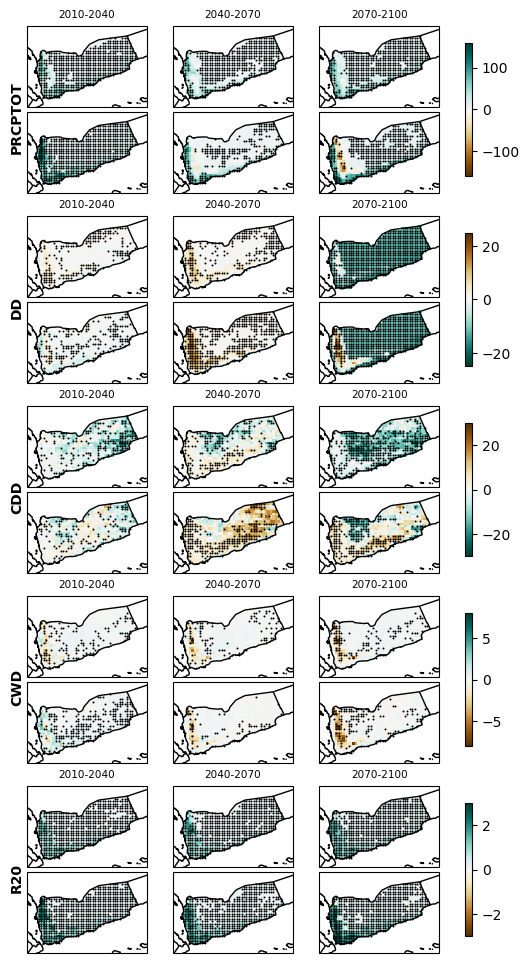

In [16]:
%%time

scenarios = ["rcp26", "rcp85"]
periods = [("2010-01-01", "2040-01-01"), ("2040-01-01", "2070-01-01"), ("2070-01-01", "2100-01-01")]

fig, axs = plot_scenarios(
    df, "pr", DOMAIN, hist, scenarios,
    periods, (min_lat, max_lat), (min_lon, max_lon), mask,
    figsize_per_model=2.25, figsize_per_row=1.125,
    spacer_height=0.35/2, hspace=0.15/2, wspace=0.08*2)

CPU times: user 1min, sys: 21.2 s, total: 1min 22s
Wall time: 49min 17s


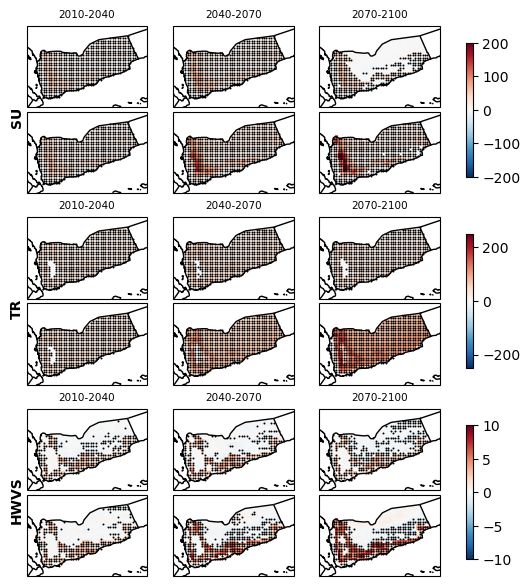

In [17]:
%%time

scenarios = ["rcp26", "rcp85"]
periods = [("2010-01-01", "2040-01-01"), ("2040-01-01", "2070-01-01"), ("2070-01-01", "2100-01-01")]

fig, axs = plot_scenarios(
    df, "temp", DOMAIN, hist, scenarios,
    periods, (min_lat, max_lat), (min_lon, max_lon), mask,
    figsize_per_model=2.25, figsize_per_row=1.125,
    spacer_height=0.35/2, hspace=0.15/2, wspace=0.08*2)